In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns",None)
sns.set_theme(style="whitegrid")

df = pd.read_csv("../data/netflix_titles.csv")
df.head()

,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,NaN,United States,"September 25, 2021",2020,PG-13,90 min,Documentaries,"As her father nears the end of his life, filmm..."
1,s2,TV Show,Blood & Water,NaN,"Ama Qamata, Khosi Ngema, Gail Mabalane, Thaban...",South Africa,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, TV Dramas, TV Mysteries","After crossing paths at a party, a Cape Town t..."
2,s3,TV Show,Ganglands,Julien Leclercq,"Sami Bouajila, Tracy Gotoas, Samuel Jouy, Nabi...",NaN,"September 24, 2021",2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act...",To protect his family from a powerful drug lor...
3,s4,TV Show,Jailbirds New Orleans,NaN,NaN,NaN,"September 24, 2021",2021,TV-MA,1 Season,"Docuseries, Reality TV","Feuds, flirtations and toilet talk go down amo..."
4,s5,TV Show,Kota Factory,NaN,"Mayur More, Jitendra Kumar, Ranjan Raj, Alam K...",India,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, Romantic TV Shows, TV ...",In a city of coaching centers known to train I...


In [2]:
df.shape

(8807, 12)

In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8807 entries, 0 to 8806
Data columns (total 12 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   show_id       8807 non-null   object
 1   type          8807 non-null   object
 2   title         8807 non-null   object
 3   director      6173 non-null   object
 4   cast          7982 non-null   object
 5   country       7976 non-null   object
 6   date_added    8797 non-null   object
 7   release_year  8807 non-null   int64 
 8   rating        8803 non-null   object
 9   duration      8804 non-null   object
 10  listed_in     8807 non-null   object
 11  description   8807 non-null   object
dtypes: int64(1), object(11)
memory usage: 825.8+ KB


In [4]:
df.isnull().sum() #this shows no. of null values in each col

show_id            0
type               0
title              0
director        2634
cast             825
country          831
date_added        10
release_year       0
rating             4
duration           3
listed_in          0
description        0
dtype: int64

In [5]:
df.duplicated().sum() # this shows no. of duplicate in dataset

np.int64(0)

In [6]:
df_clean = df.copy() # create a copy of our dataset so main data set remains untouched

In [7]:
df_clean[['director','cast','country']] = df_clean[['director','cast','country']].fillna('Unknown') # fills the missing values of col director cast and country with Unknown
df_clean = df_clean.dropna(subset=['rating','duration','date_added']) # drops the missing values of the col rating duration date_added
df_clean.isnull().sum() # checking again for missing values

show_id         0
type            0
title           0
director        0
cast            0
country         0
date_added      0
release_year    0
rating          0
duration        0
listed_in       0
description     0
dtype: int64

In [8]:
df_clean.shape # checking weather rows got deleted

(8790, 12)

In [9]:
df_clean['date_added'] = pd.to_datetime(df_clean['date_added'].str.strip()) # converting date added from str obj to datetime
df_clean['year_added'] = df_clean['date_added'].dt.year # new col with year in it
df_clean['month_added'] = df_clean['date_added'].dt.month # new coll with months in it

In [10]:
df_clean.dtypes

show_id                 object
type                    object
title                   object
director                object
cast                    object
country                 object
date_added      datetime64[ns]
release_year             int64
rating                  object
duration                object
listed_in               object
description             object
year_added               int32
month_added              int32
dtype: object

In [11]:
df_clean['duration'].head(10) # duration's values are mis of 2 things for movies it shows min and for tv shows it shows sesons so we wont be able to plot it later we can choose type either movie or shows for ploting

0       90 min
1    2 Seasons
2     1 Season
3     1 Season
4    2 Seasons
5     1 Season
6       91 min
7      125 min
8    9 Seasons
9      104 min
Name: duration, dtype: object

In [12]:
df_clean['duration_num'] = df_clean['duration'].str.extract(r'(\d+)')[0].astype(int) # extracting integer values from duration
df_clean[['type','duration','duration_num']].head()

,type,duration,duration_num
0,Movie,90 min,90
1,TV Show,2 Seasons,2
2,TV Show,1 Season,1
3,TV Show,1 Season,1
4,TV Show,2 Seasons,2


# Exploratory Data Analysis

### Chart 1: Movies vs TV Shows
How is Netflix's catalog split between movies and TV shows?

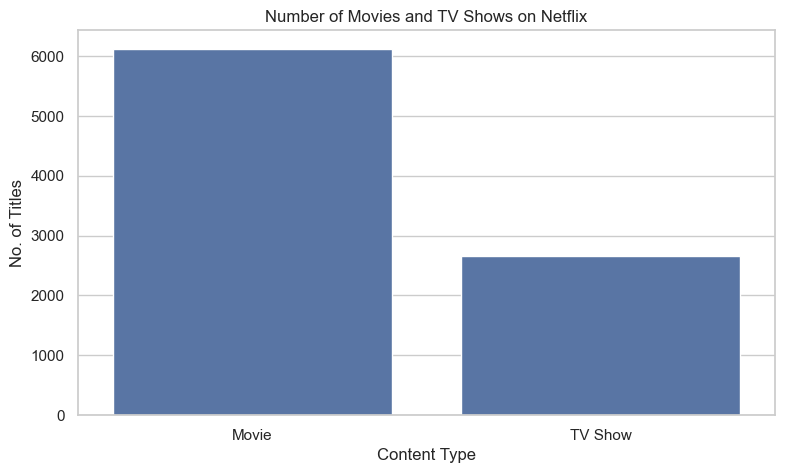

In [13]:
plt.figure(figsize = (9,5))
sns.countplot(data=df_clean,x='type')
plt.title("Number of Movies and TV Shows on Netflix")
plt.xlabel("Content Type")
plt.ylabel("No. of Titles")
plt.show()

In [14]:
df_clean['type'].value_counts()

type
Movie      6126
TV Show    2664
Name: count, dtype: int64

**Insight:** Netflix is mostly a movie library. Out of 8,790 titles, about 70% are movies and only 30% are TV shows. Since movies are measured in minutes and shows in seasons, I'll analyze them separately from here on so the comparisons stay fair.

### Chart 2: Distribution of Movie Durations
How long is a typical Netflix movie, and are there unusual lengths?

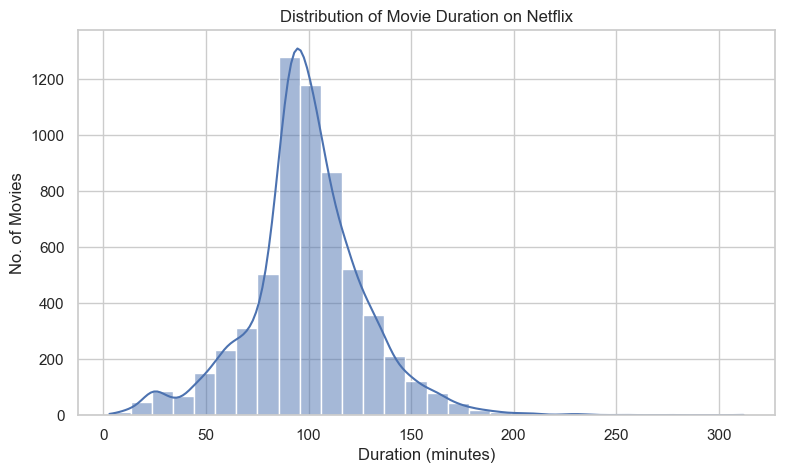

In [15]:
movies = df_clean[df_clean['type']=='Movie'] # filtering movies only
plt.figure(figsize = (9,5))
sns.histplot(data=movies,x='duration_num',bins=30,kde=True)
plt.title("Distribution of Movie Duration on Netflix")
plt.xlabel("Duration (minutes)")
plt.ylabel("No. of Movies")
plt.show()

In [16]:
movies['duration_num'].describe()

count    6126.000000
mean       99.584884
std        28.283225
min         3.000000
25%        87.000000
50%        98.000000
75%       114.000000
max       312.000000
Name: duration_num, dtype: float64

**Insight:** The typical Netflix movie runs about 98 minutes (the median), and the middle half of all movies fall between 87 and 114 minutes. A few very long films stretch the right tail, with the longest at 312 minutes, which pulls the mean slightly above the median at about 100 minutes.

### Chart 3: Titles Added Per Year
How has Netflix's content library grown over the years?

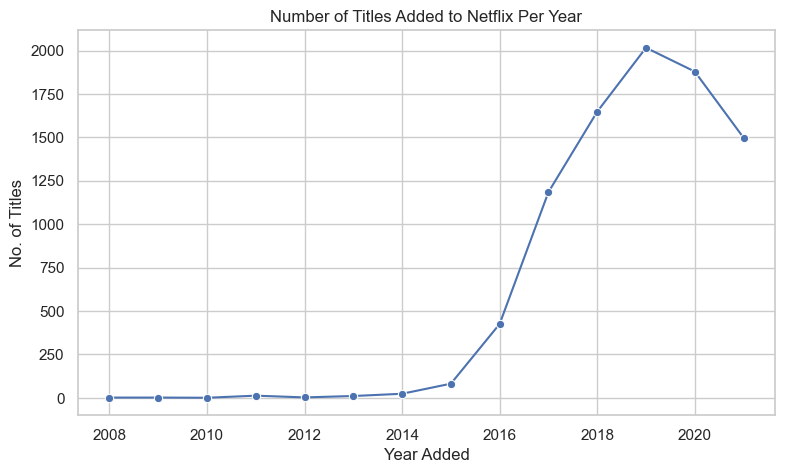

In [17]:
titles_per_year = df_clean['year_added'].value_counts().sort_index()
plt.figure(figsize = (9,5))
sns.lineplot(x=titles_per_year.index,y=titles_per_year.values,marker='o')
plt.title("Number of Titles Added to Netflix Per Year")
plt.xlabel("Year Added")
plt.ylabel("No. of Titles")
plt.show()

In [18]:
titles_per_year

year_added
2008       2
2009       2
2010       1
2011      13
2012       3
2013      11
2014      24
2015      82
2016     426
2017    1185
2018    1648
2019    2016
2020    1879
2021    1498
Name: count, dtype: int64

In [19]:
df_clean['date_added'].max()

Timestamp('2021-09-25 00:00:00')

**Insight:** Netflix added almost nothing before 2015, then growth took off: from 426 titles in 2016 to a peak of 2,016 in 2019. The dip in 2020 and 2021 shouldn't be read as a collapse. The dataset ends in September 2021, so 2021 is only about nine months of data, and 2020 was disrupted by the pandemic.

### Chart 4: Top 10 Countries by Number of Titles
Which countries produce the most content on Netflix?

In [27]:
df_clean['country'].value_counts().head(30) # checking total values in each country
# Some titles list multiple countries (e.g. "United States, India"), so we split them before counting

country
United States                    2809
India                             972
Unknown                           829
United Kingdom                    418
Japan                             243
South Korea                       199
Canada                            181
Spain                             145
France                            124
Mexico                            110
Egypt                             106
Turkey                            105
Nigeria                            95
Australia                          85
Taiwan                             81
Indonesia                          79
Brazil                             77
Philippines                        75
United Kingdom, United States      75
United States, Canada              73
Germany                            67
China                              66
Thailand                           61
Argentina                          56
Hong Kong                          53
United States, United Kingdom      47
Cana

In [26]:
countries = df_clean['country'].str.split(', ').explode() #splits and giev each row to each country
countries = countries[countries != 'Unknown'] # handling Unknowns
top_countries = countries.value_counts().head(10)
top_countries

country
United States     3680
India             1046
United Kingdom     803
Canada             445
France             393
Japan              316
Spain              232
South Korea        231
Germany            226
Mexico             169
Name: count, dtype: int64

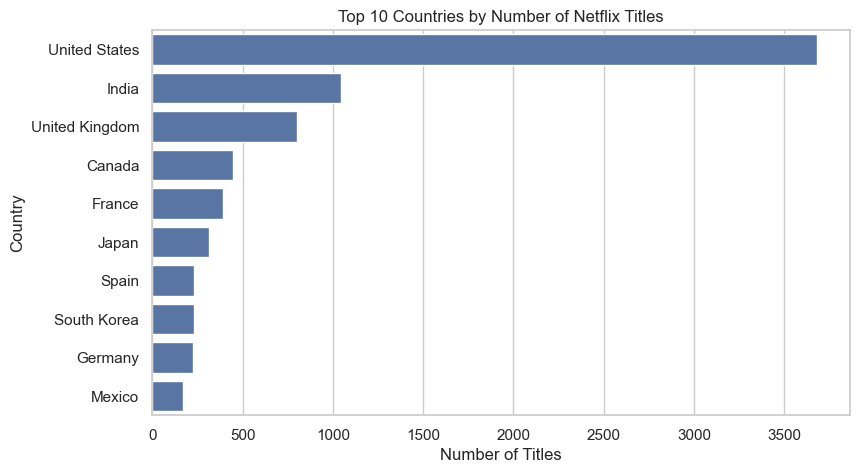

In [30]:
plt.figure(figsize = (9,5))
sns.barplot(x=top_countries.values,y=top_countries.index)
plt.title("Top 10 Countries by Number of Netflix Titles")
plt.xlabel("Number of Titles")
plt.ylabel("Country")
plt.show()

**Insight:** The United States leads by a wide margin with 3,680 titles, more than three times India in second place (1,046). The United Kingdom follows with 803, and after that no other country passes 450. Because titles with several countries are counted once per country, the totals overlap slightly, but the US-first pattern is clear.